# UIUC embeddings: sensitivity to the input distance

Starting from [`uiuc_dimension_reduction.ipynb`](uiuc_dimension_reduction.ipynb), compare the same airfoils under four geometry representations and their induced Euclidean distances. Run the baseline notebook first to create its geometry, performance, and metadata caches. This notebook reuses those inputs, with no download or aerodynamic reevaluation.

Question: how much do the input neighbourhoods and the resulting two-dimensional embeddings change when the geometry distance changes? Compare PCA, UMAP, Isomap, and diffusion maps at fixed settings. Tables and plots provide measurements; interpretation is left to the reader.

The alternatives use AeroSandbox's existing CST/Kulfan fitter and a sampled camber/thickness representation. Performance colouring remains the baseline's **NeuralFoil predictions for the original airfoils**, not measured UIUC polars or new predictions on the fitted shapes. Performance never enters the distances.

In [1]:
# If these packages are missing from the notebook kernel, run once and restart:
# %pip install umap-learn pydiffmap

In [2]:
import hashlib
import json
import platform
import sys
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import aerosandbox as asb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from pydiffmap.diffusion_map import DiffusionMap
from scipy.sparse.csgraph import connected_components
from scipy.spatial import procrustes
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.manifold import Isomap, trustworthiness
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler
from umap import UMAP

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from utils.functional_clustering import trapezoid_weights

SOURCE = ROOT / "data" / "uiuc_dimension_reduction"
DATA = ROOT / "data" / "uiuc_metric_comparison"
DATA.mkdir(parents=True, exist_ok=True)

SEED = 42
NEIGHBORS = 30
EVALUATION_NEIGHBORS = 10
CST_WEIGHTS_PER_SIDE = 8
CHORD_STATIONS = 201
DIFFUSION_ALPHA = 1.0  # Matches the current baseline notebook's estimator cell.
DIFFUSION_BANDWIDTH_FACTOR = 4.0
UMAP_MIN_DIST = 0.1
UMAP_REPEAT_SEED = 43
MAX_PAIRS = 50_000
COLOUR = "CL/CD"  # Other choices: CL, CD, confidence.

plt.rcParams.update({"figure.dpi": 120, "axes.grid": False})

## 1. Reuse the baseline inputs

Verify the stored contour features and join performance by airfoil name. All representations and methods use the same accepted airfoils in the same order. A parameter-fit failure excludes that airfoil from every comparison and is logged; reconstruction error alone does not exclude an airfoil.

In [3]:
required = [SOURCE / name for name in ["geometry.npz", "performance.csv", "run_metadata.json"]]
if not all(path.exists() for path in required):
    raise FileNotFoundError("Run uiuc_dimension_reduction.ipynb first to generate the baseline caches.")
source_metadata = json.loads(required[2].read_text())
with np.load(required[0]) as cache:
    names = cache["names"].astype(str)
    contours = cache["contours"]
    baseline_X = cache["X"]
expected_X = contours.reshape(len(contours), -1)
np.testing.assert_allclose(baseline_X, expected_X - expected_X.mean(axis=0), atol=1e-12)
if not pd.Index(names).is_unique or not np.isfinite(contours).all():
    raise ValueError("Baseline names must be unique and geometry finite.")
performance = pd.read_csv(required[1], index_col="airfoil")
if not performance.index.is_unique:
    raise ValueError("Performance cache contains duplicate names.")
performance = performance.loc[names]
print(f"Baseline: {len(names)} airfoils, {baseline_X.shape[1]} contour features")
display(pd.DataFrame([source_metadata["operating_point"]]))

Baseline: 1660 airfoils, 398 contour features


,alpha_deg,Re,Mach,n_crit,xtr_upper,xtr_lower
0,4.0,1000000.0,0.0,9.0,1.0,1.0


## 2. Alternative representations and distances

| Representation | Features and distance |
|---|---|
| Contour | Baseline flattened unit-chord `(x, y)` contour; Euclidean distance, with no variance scaling. |
| CST raw | Eight upper and eight lower CST weights, the leading-edge modification weight, and trailing-edge thickness: 18 coefficients, all included in Euclidean distance. |
| CST standardized | The same 18 coefficients, each centered and divided by its population standard deviation over the common comparison sample using `StandardScaler`. Constant columns receive scale 1. |
| Camber/thickness L2 | Camber `m(x)` and full thickness `t(x)` sampled on a common cosine-spaced chord grid. Square-root trapezoidal weights make Euclidean squared distance approximate `∫[(Δm)² + (Δt)²] dx`. Both channels have equal weight and chord units. |

[CST/Kulfan fitting](https://aerosandbox.readthedocs.io/en/master/_modules/aerosandbox/geometry/airfoil/airfoil_families.html) uses AeroSandbox's least-squares fit, fixed class exponents `N1=0.5`, `N2=1`, and leading-edge modification. First interpolate the cached original upper/lower surfaces onto the common chord grid using AeroSandbox. Fit CST to these grid points with normalization disabled. This keeps the CST basis inside its domain `[0, 1]`, even when the baseline spline repaneling has produced coordinate excursions outside the unit chord. Record their count and largest excursion; do not alter the contour reference. Camber/thickness uses these original interpolated surfaces, not the CST reconstruction. CST is a lossy representation: coefficient distances need not distinguish every original contour.

Record the CST reconstruction RMS error in upper/lower ordinates on the same chord grid, in chord units. No fitting-quality threshold is applied. High-error fits remain visible in the diagnostics.

In [4]:
x = (1 - np.cos(np.linspace(0, np.pi, CHORD_STATIONS))) / 2
weights = trapezoid_weights(x)
coefficient_columns = ([f"upper_{i}" for i in range(CST_WEIGHTS_PER_SIDE)]
                       + [f"lower_{i}" for i in range(CST_WEIGHTS_PER_SIDE)]
                       + ["leading_edge_weight", "TE_thickness"])
coefficients, camber_thickness, reconstruction_errors = [], [], []
accepted, fit_failures = [], []
original_surfaces, fitted_surfaces = [], []
outside_chord_counts, chord_excursions = [], []
for i, (name, contour) in enumerate(zip(names, contours)):
    try:
        foil = asb.Airfoil(name=name, coordinates=contour)
        camber = foil.local_camber(x)
        thickness = foil.local_thickness(x)
        original = np.stack([camber + thickness / 2, camber - thickness / 2])
        fit_contour = np.vstack([np.column_stack([x[::-1], original[0, ::-1]]),
                                 np.column_stack([x[1:], original[1, 1:]])])
        cst = asb.Airfoil(name=name, coordinates=fit_contour).to_kulfan_airfoil(
            n_weights_per_side=CST_WEIGHTS_PER_SIDE, N1=0.5, N2=1.0,
            normalize_coordinates=False, use_leading_edge_modification=True,
        )
        parameters = np.r_[cst.upper_weights, cst.lower_weights,
                           cst.leading_edge_weight, cst.TE_thickness]
        fitted = np.stack([cst.upper_coordinates(x)[:, 1], cst.lower_coordinates(x)[:, 1]])
        if not all(np.isfinite(a).all() for a in [parameters, original, fitted]):
            raise ValueError("Nonfinite parameterization or reconstruction.")
        rms = np.sqrt(np.sum((fitted - original)**2 * weights) / 2)
    except (ValueError, RuntimeError, IndexError, np.linalg.LinAlgError) as error:
        fit_failures.append({"airfoil": name, "reason": str(error)})
        continue
    accepted.append(i)
    coefficients.append(parameters)
    camber_thickness.append(np.r_[camber * np.sqrt(weights), thickness * np.sqrt(weights)])
    reconstruction_errors.append(rms)
    original_surfaces.append(original)
    fitted_surfaces.append(fitted)
    outside_chord_counts.append(int(np.count_nonzero((contour[:, 0] < 0) | (contour[:, 0] > 1))))
    chord_excursions.append(float(max(0, -contour[:, 0].min(), contour[:, 0].max() - 1)))

failures = pd.DataFrame(fit_failures, columns=["airfoil", "reason"])
failures.to_csv(DATA / "parameterization_failures.csv", index=False)
display(failures)
if len(accepted) <= NEIGHBORS or not 0 < EVALUATION_NEIGHBORS < len(accepted) / 2:
    raise ValueError("Not enough common airfoils for the selected neighborhood sizes.")
names, contours = names[accepted], contours[accepted]
performance = performance.loc[names]
coefficients = np.stack(coefficients)
scaler = StandardScaler().fit(coefficients)
representations = {
    "Contour": baseline_X[accepted],
    "CST raw": coefficients,
    "CST standardized": scaler.transform(coefficients),
    "Camber/thickness L2": np.stack(camber_thickness),
}
parameter_table = pd.DataFrame(coefficients, columns=coefficient_columns, index=names)
parameter_table.index.name = "airfoil"
parameter_table.to_csv(DATA / "cst_parameters.csv")
scaling = pd.DataFrame({"mean": scaler.mean_, "scale": scaler.scale_}, index=coefficient_columns)
scaling.to_csv(DATA / "cst_standardization.csv", index_label="coefficient")
fit_diagnostics = pd.DataFrame({"airfoil": names, "cst_surface_rms_chord": reconstruction_errors,
                                "original_points_outside_chord": outside_chord_counts,
                                "original_max_chord_excursion": chord_excursions})
fit_diagnostics.to_csv(DATA / "cst_fit_diagnostics.csv", index=False)
np.savez_compressed(DATA / "representations.npz", names=names, x=x, weights=weights,
                    **representations)
print(f"Common comparison sample: {len(names)} airfoils")
display(fit_diagnostics["cst_surface_rms_chord"].describe())
display(fit_diagnostics.nlargest(5, "cst_surface_rms_chord"))
print(f"Contours with original points outside [0, 1]: {np.count_nonzero(outside_chord_counts)}")

,airfoil,reason


Common comparison sample: 1660 airfoils


count    1660.000000
mean        0.000197
std         0.000239
min         0.000008
25%         0.000095
50%         0.000151
75%         0.000229
max         0.004557
Name: cst_surface_rms_chord, dtype: float64

,airfoil,cst_surface_rms_chord,original_points_outside_chord,original_max_chord_excursion
1379,r1145msm,0.004557,2,4.225609e-04
515,fx79w470a,0.003196,2,1.446075e-06
1600,ua79sfm,0.002710,23,1.240880e-01
1273,naca63206,0.002497,1,4.336809e-19
516,fx79w660a,0.002225,1,4.238000e-07


Contours with original points outside [0, 1]: 971


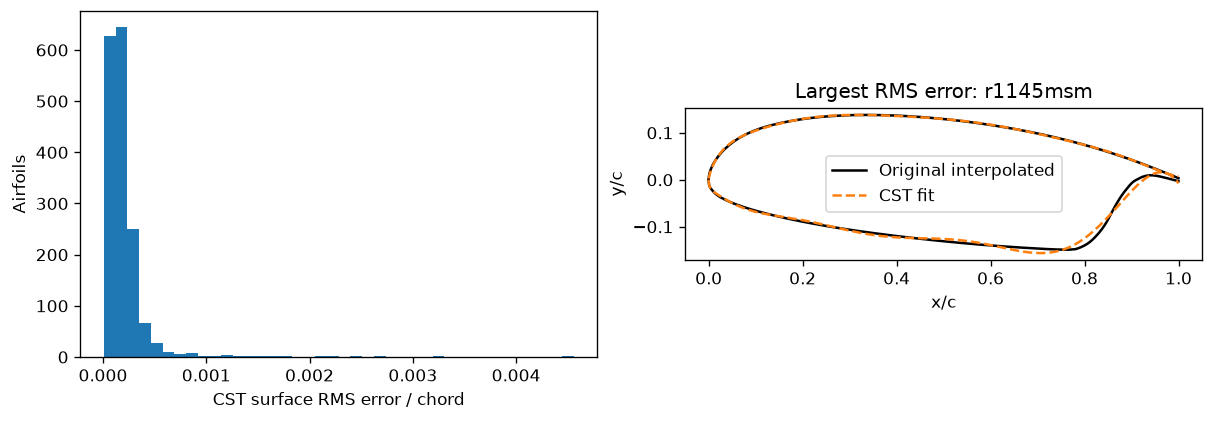

In [5]:
worst = int(np.argmax(reconstruction_errors))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), constrained_layout=True)
axes[0].hist(reconstruction_errors, bins=40)
axes[0].set(xlabel="CST surface RMS error / chord", ylabel="Airfoils")
for surface in range(2):
    axes[1].plot(x, original_surfaces[worst][surface], color="black",
                 label="Original interpolated" if surface == 0 else None)
    axes[1].plot(x, fitted_surfaces[worst][surface], "--", color="tab:orange",
                 label="CST fit" if surface == 0 else None)
axes[1].set(xlabel="x/c", ylabel="y/c", title=f"Largest RMS error: {names[worst]}", aspect="equal")
axes[1].legend()
fig.savefig(DATA / "cst_fit_check.png", dpi=180)
plt.show()

## 3. Measure changes in input distances

Neighbour overlap is the mean fraction of shared directed `EVALUATION_NEIGHBORS` nearest neighbours. Pair-distance Spearman correlation uses one fixed, uniformly sampled set of at most `MAX_PAIRS` unique airfoil pairs, reused in every comparison. These compare each representation to the original contour distance. Pair identities are saved.

Keep ties deterministic through stable sorting. The same rule is used for every representation. Neighbour graphs use the embedding fit's `NEIGHBORS`, independently of the evaluation neighbourhood size.

In [6]:
pair_i, pair_j = np.triu_indices(len(names), 1)
if len(pair_i) > MAX_PAIRS:
    selection = np.random.default_rng(SEED).choice(len(pair_i), MAX_PAIRS, replace=False)
    pair_i, pair_j = pair_i[selection], pair_j[selection]
pd.DataFrame({"airfoil_1": names[pair_i], "airfoil_2": names[pair_j]}).to_csv(
    DATA / "evaluated_pairs.csv", index=False
)
input_distances, input_neighbors, input_rows = {}, {}, []
for representation, features in representations.items():
    distances = squareform(pdist(features))
    if not np.isfinite(distances).all() or np.median(distances[pair_i, pair_j]) <= 0:
        raise ValueError(f"Invalid distances: {representation}")
    input_distances[representation] = distances
    ranked = distances.copy()
    np.fill_diagonal(ranked, np.inf)
    input_neighbors[representation] = np.argsort(ranked, axis=1, kind="stable")[:, :EVALUATION_NEIGHBORS]
    graph = kneighbors_graph(features, n_neighbors=NEIGHBORS, mode="connectivity")
    reference = input_neighbors["Contour"]
    overlap = np.mean([np.isin(a, b).mean() for a, b in zip(input_neighbors[representation], reference)])
    correlation = spearmanr(distances[pair_i, pair_j], input_distances["Contour"][pair_i, pair_j]).statistic
    input_rows.append({"representation": representation, "feature_count": features.shape[1],
                       "distance_spearman_vs_contour": float(correlation),
                       "neighbor_overlap_vs_contour": float(overlap),
                       "fit_graph_components": int(connected_components(graph, directed=False)[0])})
input_comparison = pd.DataFrame(input_rows).set_index("representation")
input_comparison.to_csv(DATA / "input_distance_comparison.csv")
display(input_comparison.round(4))

,feature_count,distance_spearman_vs_contour,neighbor_overlap_vs_contour,fit_graph_components
representation,,,,
Contour,398,1.0000,1.0000,1
CST raw,18,0.5434,0.1674,1
CST standardized,18,0.6118,0.1939,1
Camber/thickness L2,402,0.9244,0.6925,1


## 4. Fit the four methods for each representation

All distances are Euclidean **in the chosen representation**: this changes the geometry of the original input space without custom estimator implementations. PCA fits the representation's feature matrix; ordinary PCA does not accept an arbitrary distance matrix. UMAP, Isomap, and pyDiffMap use those same features and Euclidean distances.

Refit the contour reference on the common sample rather than mixing embeddings of different samples. Keep 2D output, neighbour counts, UMAP `min_dist`, and diffusion normalization exponent fixed. UMAP uses the same random initialization and seed in each representation to reduce initialization confounding. This differs from the baseline notebook's default spectral initialization. A second UMAP contour run with seed 43 is a stochastic control, not a confidence interval.

For each diffusion fit use `DIFFUSION_BANDWIDTH_FACTOR * median(all squared pairwise distances) / 4`, applied to that representation, with the same factor 4 for every representation. In the initial run on 1,660 airfoils, factor 1 (the baseline rule) failed to converge for both CST representations; factor 4 converged. These initial failures are numerical observations, not comparisons of embedding quality. Thus a global rescaling of all input distances does not alone change the diffusion kernel. The pyDiffMap Gaussian kernel is `exp(-d² / (4ε))`; returned coordinates use its generator-eigenvalue scaling. Warnings and fit failures are retained; failed fits have no embedding and are logged.

In [7]:
embeddings, fit_rows = {}, []
for representation, features in representations.items():
    distances = input_distances[representation]
    epsilon = float(DIFFUSION_BANDWIDTH_FACTOR * np.median(distances[np.triu_indices(len(names), 1)]**2) / 4)
    models = {
        "PCA": PCA(n_components=2, svd_solver="full"),
        "UMAP": UMAP(n_components=2, n_neighbors=NEIGHBORS, min_dist=UMAP_MIN_DIST,
                     metric="euclidean", init="random", random_state=SEED, n_jobs=1),
        "Isomap": Isomap(n_components=2, n_neighbors=NEIGHBORS, eigen_solver="arpack"),
        "Diffusion maps": DiffusionMap.from_sklearn(
            n_evecs=2, k=NEIGHBORS + 1, alpha=DIFFUSION_ALPHA,
            epsilon=epsilon, metric="euclidean",
        ),
    }
    for method, model in models.items():
        np.random.seed(SEED)
        row = {"representation": representation, "method": method, "seed": SEED,
               "status": "ok", "error": "", "diffusion_epsilon": np.nan,
               "diffusion_kernel_components": np.nan, "pca_variance_2d": np.nan}
        try:
            embedding = model.fit_transform(features)
            if embedding.shape != (len(names), 2) or not np.isfinite(embedding).all():
                raise ValueError("Nonfinite or incorrectly shaped embedding.")
            embeddings[representation, method] = embedding
            if method == "PCA":
                row["pca_variance_2d"] = float(model.explained_variance_ratio_.sum())
            if method == "Diffusion maps":
                row["diffusion_epsilon"] = epsilon
                row["diffusion_kernel_components"] = int(connected_components(model.kernel_matrix, directed=False)[0])
        except (ValueError, RuntimeError, np.linalg.LinAlgError) as error:
            row.update(status="failed", error=str(error))
        fit_rows.append(row)
        print(f"{representation} / {method}: {row['status']}", flush=True)

control = UMAP(n_components=2, n_neighbors=NEIGHBORS, min_dist=UMAP_MIN_DIST,
               metric="euclidean", init="random", random_state=UMAP_REPEAT_SEED, n_jobs=1)
try:
    control_embedding = control.fit_transform(representations["Contour"])
    if control_embedding.shape != (len(names), 2) or not np.isfinite(control_embedding).all():
        raise ValueError("Invalid UMAP control embedding.")
    embeddings["Contour seed control", "UMAP"] = control_embedding
    fit_rows.append({"representation": "Contour seed control", "method": "UMAP",
                     "seed": UMAP_REPEAT_SEED, "status": "ok", "error": ""})
except (ValueError, RuntimeError) as error:
    fit_rows.append({"representation": "Contour seed control", "method": "UMAP",
                     "seed": UMAP_REPEAT_SEED, "status": "failed", "error": str(error)})
fit_status = pd.DataFrame(fit_rows)
fit_status.to_csv(DATA / "fit_status.csv", index=False)
display(fit_status)
if not all(("Contour", method) in embeddings for method in models):
    raise RuntimeError("A contour reference fit failed; see fit_status.csv before comparing embeddings.")

Contour / PCA: ok
Contour / UMAP: ok
Contour / Isomap: ok
Contour / Diffusion maps: ok
CST raw / PCA: ok
CST raw / UMAP: ok
CST raw / Isomap: ok
CST raw / Diffusion maps: ok
CST standardized / PCA: ok
CST standardized / UMAP: ok
CST standardized / Isomap: ok
CST standardized / Diffusion maps: ok
Camber/thickness L2 / PCA: ok
Camber/thickness L2 / UMAP: ok
Camber/thickness L2 / Isomap: ok
Camber/thickness L2 / Diffusion maps: ok


,representation,method,seed,status,error,diffusion_epsilon,diffusion_kernel_components,pca_variance_2d
0,Contour,PCA,42,ok,,NaN,NaN,0.898993
1,Contour,UMAP,42,ok,,NaN,NaN,NaN
2,Contour,Isomap,42,ok,,NaN,NaN,NaN
3,Contour,Diffusion maps,42,ok,,0.104810,1.0,NaN
4,CST raw,PCA,42,ok,,NaN,NaN,0.648522
5,CST raw,UMAP,42,ok,,NaN,NaN,NaN
6,CST raw,Isomap,42,ok,,NaN,NaN,NaN
7,CST raw,Diffusion maps,42,ok,,0.605130,1.0,NaN
8,CST standardized,PCA,42,ok,,NaN,NaN,0.540092
9,CST standardized,UMAP,42,ok,,NaN,NaN,NaN


## 5. Evaluate embedding preservation and changes

For each embedding measure:

- **Own-input trustworthiness**: [scikit-learn's rank-based score](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.trustworthiness.html), between 0 and 1; higher means fewer unexpected neighbours under its own input metric.
- **Own-input neighbour recall** and **contour-input neighbour recall**: overlap of 2D neighbours with the corresponding input neighbours, or with the original contour neighbours. They answer different reference questions.
- **Own-input distance Spearman**: sampled input-versus-embedding pair-distance correlation.
- **Embedding neighbour overlap** and **embedding distance Spearman versus contour embedding**: compare each result with the same method's 2D contour reference, using the same airfoil identities.
- **Procrustes disparity**: [SciPy alignment](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.procrustes.html) removes translation, rotation/reflection, and global scale before summing squared pointwise differences. Zero means identical configurations up to alignment. Save per-airfoil aligned displacement too.

Comparisons with the contour reference describe changes, not whether a metric is scientifically preferable. UMAP control rows measure one change of seed on an unchanged input space. Missing method fits remain in `fit_status.csv`; they cannot contribute numerical scores.

In [8]:
embedding_distances, embedding_neighbors = {}, {}
for key, embedding in embeddings.items():
    distances = squareform(pdist(embedding))
    embedding_distances[key] = distances
    ranked = distances.copy()
    np.fill_diagonal(ranked, np.inf)
    embedding_neighbors[key] = np.argsort(ranked, axis=1, kind="stable")[:, :EVALUATION_NEIGHBORS]

comparison_rows, point_tables = [], []
for (representation, method), embedding in embeddings.items():
    input_representation = "Contour" if representation == "Contour seed control" else representation
    own_neighbors = input_neighbors[input_representation]
    latent_neighbors = embedding_neighbors[representation, method]
    baseline_key = ("Contour", method)
    reference, aligned, disparity = procrustes(embeddings[baseline_key], embedding)
    displacement = np.linalg.norm(reference - aligned, axis=1)
    row = {"representation": representation, "method": method,
           "own_input_trustworthiness": float(trustworthiness(
               input_distances[input_representation], embedding,
               n_neighbors=EVALUATION_NEIGHBORS, metric="precomputed")),
           "own_input_neighbor_recall": float(np.mean([np.isin(a, b).mean() for a, b in zip(latent_neighbors, own_neighbors)])),
           "contour_input_neighbor_recall": float(np.mean([np.isin(a, b).mean() for a, b in zip(latent_neighbors, input_neighbors["Contour"])])),
           "own_input_distance_spearman": float(spearmanr(
               embedding_distances[representation, method][pair_i, pair_j],
               input_distances[input_representation][pair_i, pair_j]).statistic),
           "embedding_neighbor_overlap_vs_contour": float(np.mean([
               np.isin(a, b).mean() for a, b in zip(latent_neighbors, embedding_neighbors[baseline_key])])),
           "embedding_distance_spearman_vs_contour": float(spearmanr(
               embedding_distances[representation, method][pair_i, pair_j],
               embedding_distances[baseline_key][pair_i, pair_j]).statistic),
           "procrustes_disparity_vs_contour": float(disparity)}
    comparison_rows.append(row)
    points = pd.DataFrame({"airfoil": names, "representation": representation, "method": method,
                           "coordinate_1": embedding[:, 0], "coordinate_2": embedding[:, 1],
                           "aligned_1": aligned[:, 0], "aligned_2": aligned[:, 1],
                           "aligned_displacement": displacement})
    points = points.join(performance, on="airfoil")
    point_tables.append(points)
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(DATA / "embedding_comparison.csv", index=False)
pd.concat(point_tables, ignore_index=True).to_csv(DATA / "embeddings_and_performance.csv", index=False)
display(comparison.set_index(["method", "representation"]).round(4))
print(f"Chance neighbour overlap: {EVALUATION_NEIGHBORS / (len(names) - 1):.4f}")

,,own_input_trustworthiness,own_input_neighbor_recall,contour_input_neighbor_recall,own_input_distance_spearman,embedding_neighbor_overlap_vs_contour,embedding_distance_spearman_vs_contour,procrustes_disparity_vs_contour
method,representation,,,,,,,
PCA,Contour,0.9739,0.3992,0.3992,0.9884,1.0000,1.0000,0.0000
UMAP,Contour,0.9821,0.5114,0.5114,0.8051,1.0000,1.0000,0.0000
Isomap,Contour,0.9746,0.3987,0.3987,0.9857,1.0000,1.0000,0.0000
Diffusion maps,Contour,0.9725,0.3578,0.3578,0.8074,1.0000,1.0000,0.0000
PCA,CST raw,0.8372,0.1432,0.0302,0.8507,0.0216,0.2024,0.9352
UMAP,CST raw,0.9202,0.3549,0.1027,0.4272,0.0793,0.3682,0.7898
Isomap,CST raw,0.8356,0.1526,0.0361,0.8476,0.0254,0.2007,0.9526
Diffusion maps,CST raw,0.8151,0.1374,0.0380,0.6204,0.0272,0.1221,0.9902
PCA,CST standardized,0.7937,0.1162,0.0299,0.7811,0.0226,0.2125,0.9169


Chance neighbour overlap: 0.0060


## 6. Inspect the embeddings and comparison scores

Rows are methods; columns are input representations. Colour limits use the complete finite range and are shared across all panels. Grey points have missing performance. Axes use each embedding's own units and scale, with no Procrustes alignment in this plot. Change `COLOUR` above to inspect another performance value.

The score heatmaps compare the four main representations. The separate UMAP seed-control row is available in the table above. Full contour-reference self-comparisons provide sanity checks: embedding overlap and correlation should be 1, and Procrustes disparity should be numerically zero.

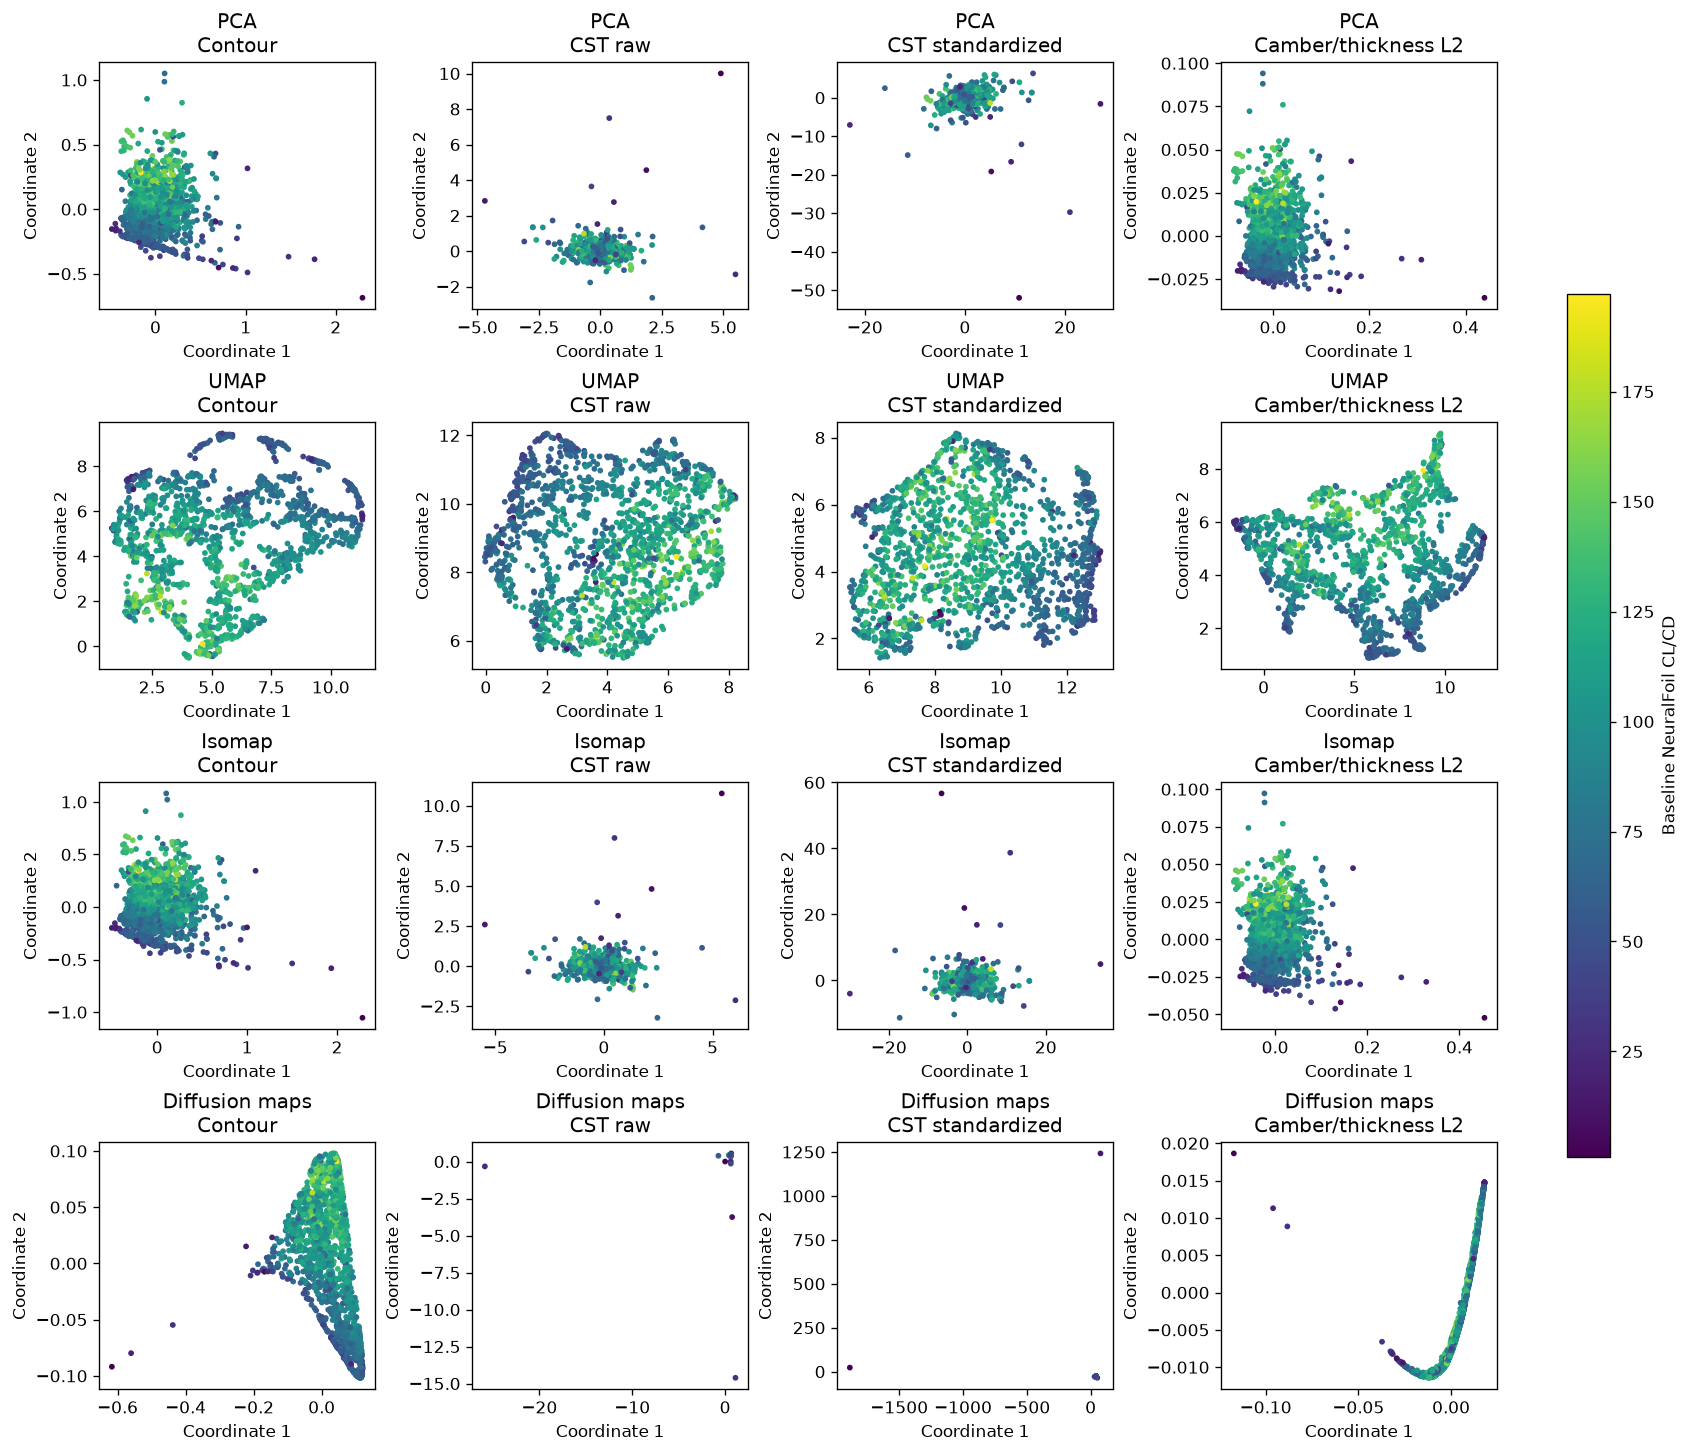

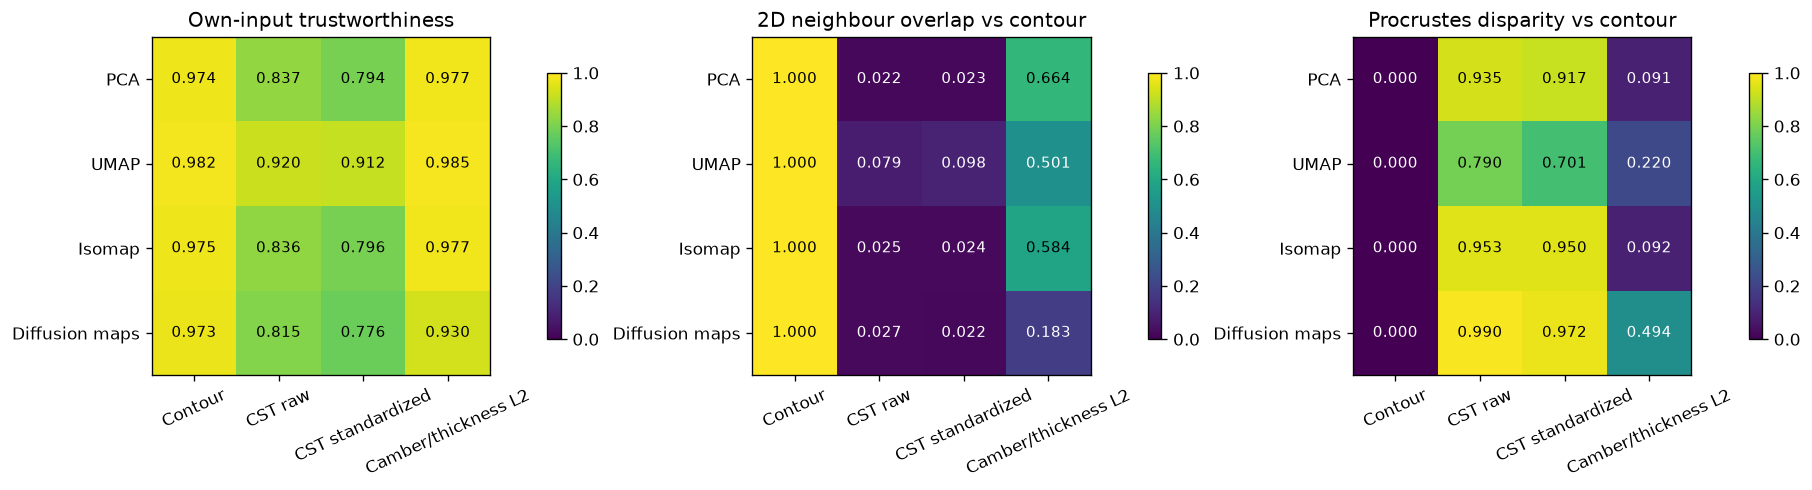

In [9]:
methods = ["PCA", "UMAP", "Isomap", "Diffusion maps"]
values = performance.loc[names, COLOUR].to_numpy()
finite = np.isfinite(values)
if not finite.any():
    raise ValueError(f"No finite colour values for {COLOUR}.")
norm = plt.Normalize(values[finite].min(), values[finite].max())
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("lightgrey")
fig, axes = plt.subplots(4, 4, figsize=(14, 12), constrained_layout=True)
for row, method in enumerate(methods):
    for col, representation in enumerate(representations):
        ax = axes[row, col]
        key = (representation, method)
        ax.set(title=f"{method}\n{representation}")
        if key not in embeddings:
            ax.text(0.5, 0.5, "Fit failed: see fit_status", ha="center", transform=ax.transAxes)
            continue
        points = ax.scatter(*embeddings[key].T, c=np.ma.masked_invalid(values), cmap=cmap,
                            norm=norm, s=6, rasterized=True, plotnonfinite=True)
        ax.set(xlabel="Coordinate 1", ylabel="Coordinate 2", title=f"{method}\n{representation}")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes.ravel().tolist(),
             label=f"Baseline NeuralFoil {COLOUR}", shrink=0.65)
fig.savefig(DATA / "metric_embeddings.png", dpi=180)
plt.show()

score_columns = ["own_input_trustworthiness", "embedding_neighbor_overlap_vs_contour",
                 "procrustes_disparity_vs_contour"]
score_titles = ["Own-input trustworthiness", "2D neighbour overlap vs contour", "Procrustes disparity vs contour"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, score, title in zip(axes, score_columns, score_titles):
    table = comparison.pivot(index="method", columns="representation", values=score).reindex(
        index=methods, columns=list(representations)
    )
    image = ax.imshow(table.to_numpy(), vmin=0, vmax=1, cmap="viridis")
    ax.set(xticks=np.arange(4), xticklabels=list(representations),
           yticks=np.arange(4), yticklabels=methods, title=title)
    ax.tick_params(axis="x", labelrotation=25)
    for i in range(4):
        for j in range(4):
            value = table.iloc[i, j]
            ax.text(j, i, f"{value:.3f}" if np.isfinite(value) else "failed", ha="center", va="center",
                    color="black" if not np.isfinite(value) or value > 0.55 else "white", fontsize=9)
    fig.colorbar(image, ax=ax, shrink=0.75)
fig.savefig(DATA / "embedding_comparison_scores.png", dpi=180)
plt.show()

In [10]:
self_checks = comparison.loc[comparison["representation"] == "Contour"]
np.testing.assert_allclose(self_checks["embedding_neighbor_overlap_vs_contour"], 1)
np.testing.assert_allclose(self_checks["embedding_distance_spearman_vs_contour"], 1)
np.testing.assert_allclose(self_checks["procrustes_disparity_vs_contour"], 0, atol=1e-12)
metadata = {
    "run_utc": datetime.now(timezone.utc).isoformat(),
    "baseline_notebook": "uiuc_dimension_reduction.ipynb",
    "source_files_sha256": {path.name: hashlib.sha256(path.read_bytes()).hexdigest() for path in required},
    "source_metadata": source_metadata,
    "airfoils": len(names), "parameterization_failures": len(failures),
    "seed": SEED, "neighbors": NEIGHBORS, "evaluation_neighbors": EVALUATION_NEIGHBORS,
    "evaluated_pair_count": len(pair_i), "max_pairs": MAX_PAIRS,
    "cst": {"weights_per_side": CST_WEIGHTS_PER_SIDE, "N1": 0.5, "N2": 1.0,
            "leading_edge_modification": True, "normalize_coordinates": False, "fit_grid": "common cosine-spaced chord stations"},
    "chord_stations": CHORD_STATIONS, "camber_thickness_channel_weights": [1, 1],
    "umap": {"min_dist": UMAP_MIN_DIST, "init": "random", "repeat_seed": UMAP_REPEAT_SEED},
    "diffusion_alpha": DIFFUSION_ALPHA, "diffusion_bandwidth_factor": DIFFUSION_BANDWIDTH_FACTOR,
    "diffusion_epsilon": "factor * median all squared pairwise distances / 4",
    "colour": COLOUR, "successful_embeddings": len(embeddings),
    "python": platform.python_version(),
    "versions": {package: version(package) for package in
                 ["aerosandbox", "numpy", "pandas", "scipy", "matplotlib",
                  "scikit-learn", "umap-learn", "pydiffmap"]},
}
(DATA / "run_metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
print(f"Saved comparison inputs, fitted coefficients, diagnostics, embeddings, figures and metadata to {DATA}")

Saved comparison inputs, fitted coefficients, diagnostics, embeddings, figures and metadata to /home/rraanto/programming/perso/aerodynamic-learning/data/uiuc_metric_comparison
